# Cuaderno: trayectorias de un proyectil

Este cuaderno calcula y dibuja la trayectoria de un proyectil lanzado con distintos ángulos. Puedes cambiar los valores de la primera celda de código y volver a ejecutar todo el cuaderno para ver el efecto.

## Datos del lanzamiento

Velocidad inicial en m/s y ángulos en grados:

In [1]:
v0 = 20                  # velocidad inicial (m/s)
angulos = [30, 45, 60]   # ángulos de lanzamiento (grados)
g = 9.81                 # gravedad (m/s²)

## Cálculo

Para cada ángulo, el tiempo de vuelo es $t_v = 2 v_0 \sin\theta / g$, y la posición en cada instante sale de las ecuaciones del movimiento:

In [2]:
import numpy as np

def trayectoria(v0, angulo, g=9.81, puntos=100):
    theta = np.radians(angulo)
    t_vuelo = 2 * v0 * np.sin(theta) / g
    t = np.linspace(0, t_vuelo, puntos)
    x = v0 * np.cos(theta) * t
    y = v0 * np.sin(theta) * t - 0.5 * g * t**2
    return x, y

for a in angulos:
    x, y = trayectoria(v0, a, g)
    print(f"{a:>3}°  alcance = {x[-1]:5.1f} m   altura máxima = {y.max():4.1f} m")

 30°  alcance =  35.3 m   altura máxima =  5.1 m
 45°  alcance =  40.8 m   altura máxima = 10.2 m
 60°  alcance =  35.3 m   altura máxima = 15.3 m


## Gráfica

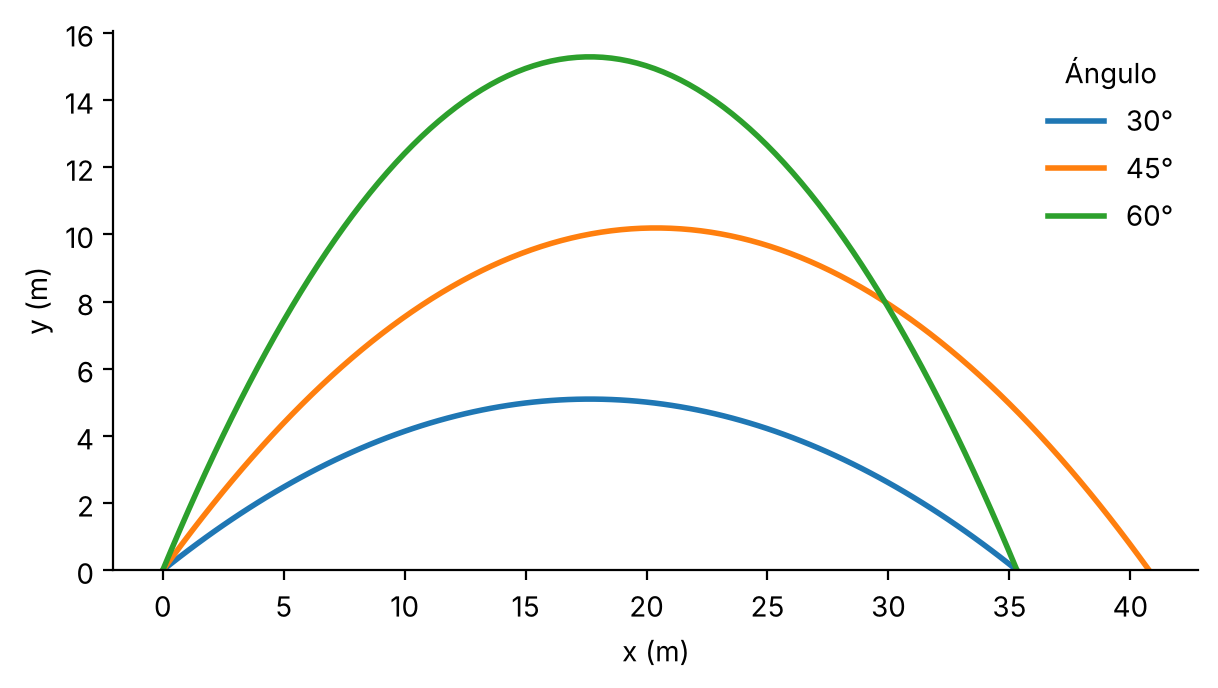

In [3]:
#| label: fig-nb-trayectorias
#| caption: Trayectorias calculadas en el cuaderno.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for a in angulos:
    x, y = trayectoria(v0, a, g)
    ax.plot(x, y, label=f"{a}°", linewidth=2)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_ylim(bottom=0)
ax.legend(title="Ángulo", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Tabla de alcances

Una salida de texto también se puede citar e incrustar en otras páginas:

In [4]:
#| label: tabla-nb-alcances
print("ángulo  alcance (m)")
for a in range(15, 90, 15):
    x, _ = trayectoria(v0, a, g)
    print(f"{a:>5}°  {x[-1]:10.1f}")

ángulo  alcance (m)
   15°        20.4
   30°        35.3
   45°        40.8
   60°        35.3
   75°        20.4
